Brayden Yow  
09/27/2026  
lab 6 -- Spinning & Rolling Objects

In [3]:
import numpy as np
import matplotlib.pyplot as plt

**Part A — The Physical Pendulum**

In [4]:
# --- 1. Parameters & Constants ---
m, g, d = 1.0, 9.81, 0.5
I = (1/3) * m * (2*d)**2    # Rod of length 2d about its end
dt = 0.001
n_steps = 10000

# Calculate natural frequency for the small-angle overlay
Omega = np.sqrt((m * g * d) / I)

# --- 2. Initialize Tracking Arrays ---
t_arr = np.zeros(n_steps)
theta_arr = np.zeros(n_steps)

# Initial conditions (Release from rest at 0.3 rad)
theta = 0.3
omega = 0.0

# --- 3. Simulation Loop ---
for i in range(n_steps):
    # Record the current state before updating
    t_arr[i] = i * dt
    theta_arr[i] = theta
    
    # Take an Euler-Cromer step
    theta, omega = rotate_step(theta, omega, torque(theta), I, dt)

# --- 4. Analytical Small-Angle Prediction ---
theta_analytical = 0.3 * np.cos(Omega * t_arr)

# --- 5. Plotting ---
plt.figure(figsize=(10, 5))
plt.plot(t_arr, theta_arr, label="Simulation (Euler-Cromer)", color="blue")
plt.plot(t_arr, theta_analytical, label="Small-Angle Prediction", color="orange", linestyle="--")
plt.xlabel("Time (s)")
plt.ylabel("Angle $\theta$ (rad)")
plt.title(r"Physical Pendulum - Small Angle ($\theta_0 = 0.3$ rad)")
plt.legend()
plt.grid(True)
plt.show()


NameError: name 'rotate_step' is not defined

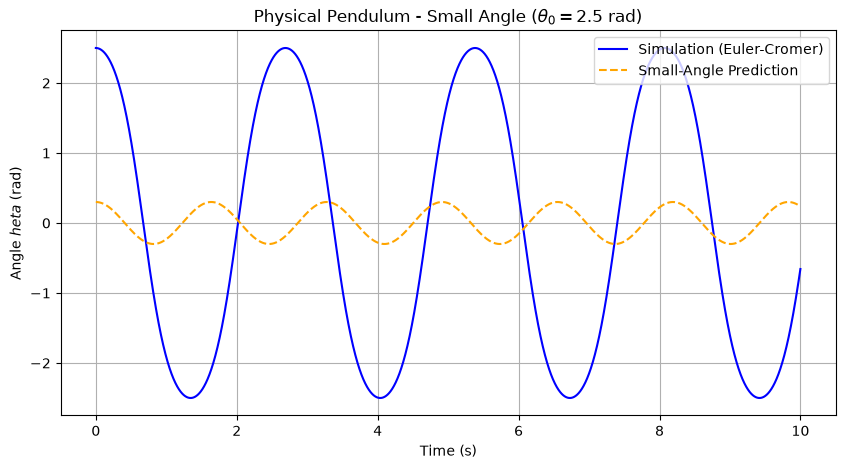

In [7]:
def rotate_step(theta, omega, torque, I, dt):
    """Euler-Cromer step for rotation."""
    alpha = torque / I
    omega = omega + alpha * dt      # angular velocity first
    theta = theta + omega * dt      # then angle (Euler-Cromer)
    return theta, omega

def torque(theta):
    return -m * g * d * np.sin(theta)

theta, omega = 0.5, 0.0   # released from 0.5 rad
dt = 0.001
for _ in range(10000):
    theta, omega = rotate_step(theta, omega, torque(theta), I, dt)

# --- 1. Parameters & Constants ---
m, g, d = 1.0, 9.81, 0.5
I = (1/3) * m * (2*d)**2    # Rod of length 2d about its end
dt = 0.001
n_steps = 10000

# Calculate natural frequency for the small-angle overlay
Omega = np.sqrt((m * g * d) / I)

# --- 2. Initialize Tracking Arrays ---
t_arr = np.zeros(n_steps)
theta_arr = np.zeros(n_steps)

# Initial conditions (Release from rest at 2.5 rad)
theta = 2.5
omega = 0.0

# --- 3. Simulation Loop ---
for i in range(n_steps):
    # Record the current state before updating
    t_arr[i] = i * dt
    theta_arr[i] = theta
    
    # Take an Euler-Cromer step
    theta, omega = rotate_step(theta, omega, torque(theta), I, dt)

# --- 4. Analytical Small-Angle Prediction ---
theta_analytical = 0.3 * np.cos(Omega * t_arr)

# --- 5. Plotting ---
plt.figure(figsize=(10, 5))
plt.plot(t_arr, theta_arr, label="Simulation (Euler-Cromer)", color="blue")
plt.plot(t_arr, theta_analytical, label="Small-Angle Prediction", color="orange", linestyle="--")
plt.xlabel("Time (s)")
plt.ylabel("Angle $\theta$ (rad)")
plt.title(r"Physical Pendulum - Small Angle ($\theta_0 = 2.5$ rad)")
plt.legend()
plt.grid(True)
plt.show()


**Interpret**:  At large amplitude, is the real period longer or shorter than the small-angle prediction?  Explain the connection to the nonlinear pendulum you saw in Lab 3.

At the large amplitude the small angle approximation breaks and the period becomes larger. From lab 3 the period of the pendulum broke when trying larger angles than allows for the approximation of sin ($\theta$) $\approx$ $\theta$


**Part B — The Rolling Race**

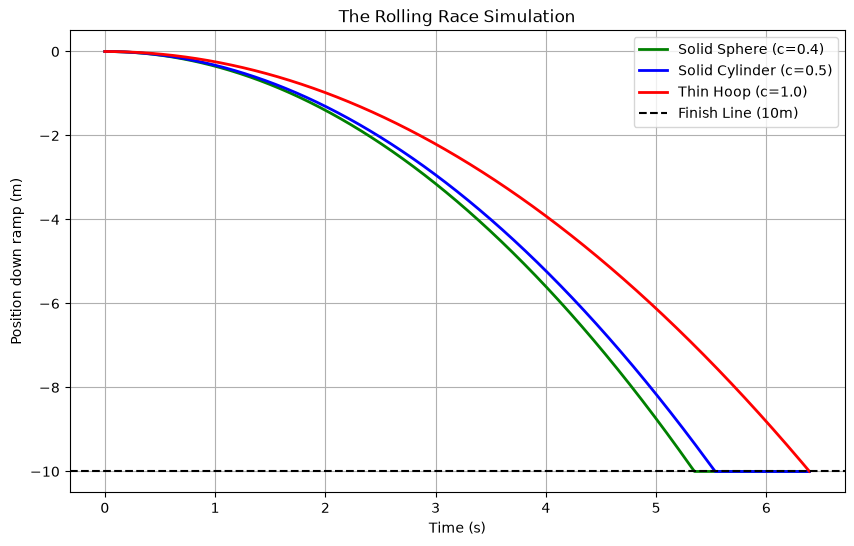

In [14]:
# --- 1. Define Physics Constants & Ramp Geometry ---
g = 9.81         # Gravity (m/s^2)
phi = 0.1        # Ramp angle (radians)
ramp_length = -10.0 # Length of the race track (meters)

# Shape coefficients (c)
c_sphere = 0.4
c_cylinder = 0.5
c_hoop = 1.0

# Calculate constant accelerations
a_sphere = (g * np.sin(phi)) / (1 + c_sphere)
a_cylinder = (g * np.sin(phi)) / (1 + c_cylinder)
a_hoop = (g * np.sin(phi)) / (1 + c_hoop)

# --- 2. Simulation Loop Parameters ---
dt = 0.001
t = 0.0

# Initialize positions and velocities
x_sphere, v_sphere = 0.0, 0.0
x_cylinder, v_cylinder = 0.0, 0.0
x_hoop, v_hoop = 0.0, 0.0

# Tracking lists for plotting
t_history = []
x_sphere_hist = []
x_cylinder_hist = []
x_hoop_hist = []

# --- 3. Run the Race ---
# Loop continues until the slowest object (the hoop) finishes the ramp
while x_hoop > ramp_length:
    # Track history
    t_history.append(t)
    x_sphere_hist.append(x_sphere)
    x_cylinder_hist.append(x_cylinder)
    x_hoop_hist.append(x_hoop)
    
    # Euler-Cromer steps (only update if they haven't finished yet)
    if x_sphere > ramp_length:
        v_sphere += a_sphere * dt
        x_sphere -= v_sphere * dt
        
    if x_cylinder > ramp_length:
        v_cylinder += a_cylinder * dt
        x_cylinder -= v_cylinder * dt
        
    if x_hoop > ramp_length:
        v_hoop += a_hoop * dt
        x_hoop -= v_hoop * dt
        
    t += dt

# --- 4. Plot the Race Results ---
plt.figure(figsize=(10, 6))
plt.plot(t_history, x_sphere_hist, label="Solid Sphere (c=0.4)", color="green", linewidth=2)
plt.plot(t_history, x_cylinder_hist, label="Solid Cylinder (c=0.5)", color="blue", linewidth=2)
plt.plot(t_history, x_hoop_hist, label="Thin Hoop (c=1.0)", color="red", linewidth=2)

plt.axhline(y=ramp_length, color='black', linestyle='--', label="Finish Line (10m)")
plt.xlabel("Time (s)")
plt.ylabel("Position down ramp (m)")
plt.title("The Rolling Race Simulation")
plt.legend()
plt.grid(True)
plt.show()


Distance is set to negative to have curves going down due to preference in how it looks

--- ENERGY REPORT: SOLID SPHERE ---
Total Energy Conservation Error: 1.8699e-02%
Empirical Rotational Energy Fraction: 0.2857
Theoretical Rotational Fraction (c / (1+c)): 0.2857


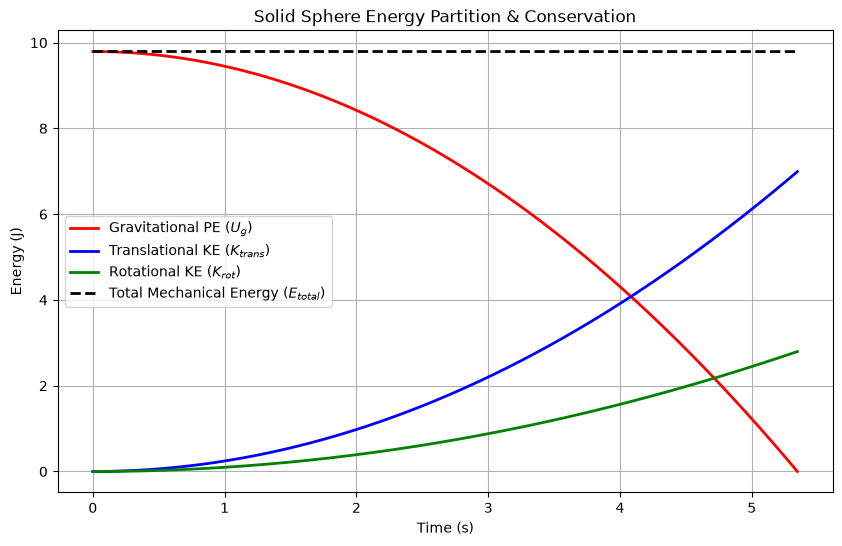

In [15]:
# --- 1. Parameters for Solid Sphere Energy Calculation ---
m = 1.0           # Mass
R = 1.0           # Radius
c_sphere = 0.4    # Shape factor for solid sphere
I_sphere = c_sphere * m * R**2

# Re-run simulation loop to explicitly track energy components
t = 0.0
x_sphere = 0.0
v_sphere = 0.0

t_energy = []
ke_trans = []
ke_rot = []
pe_grav = []
e_total = []

while x_sphere > ramp_length:
    # Calculate current height (h) relative to the finish line
    # Vertical height = distance remaining * sin(phi)
    dist_remaining = x_sphere - ramp_length
    h = dist_remaining * np.sin(phi)
    
    # Calculate angular velocity (omega = v / R)
    omega = v_sphere / R
    
    # Energy Equations
    E_trans = 0.5 * m * v_sphere**2
    E_rot = 0.5 * I_sphere * omega**2
    E_grav = m * g * h
    E_tot = E_trans + E_rot + E_grav
    
    # Store arrays for tracking
    t_energy.append(t)
    ke_trans.append(E_trans)
    ke_rot.append(E_rot)
    pe_grav.append(E_grav)
    e_total.append(E_tot)
    
    # Kinematic Step
    v_sphere += a_sphere * dt
    x_sphere -= v_sphere * dt
    t += dt

# --- 2. Print Energy Partition Verification Results ---
final_rot_fraction = ke_rot[-1] / (ke_trans[-1] + ke_rot[-1])
theoretical_fraction = c_sphere / (1 + c_sphere)
total_energy_loss = np.abs(e_total[0] - e_total[-1]) / e_total[0] * 100

print("--- ENERGY REPORT: SOLID SPHERE ---")
print(f"Total Energy Conservation Error: {total_energy_loss:.4e}%")
print(f"Empirical Rotational Energy Fraction: {final_rot_fraction:.4f}")
print(f"Theoretical Rotational Fraction (c / (1+c)): {theoretical_fraction:.4f}")

# --- 3. Plotting the Energy Transitions ---
plt.figure(figsize=(10, 6))
plt.plot(t_energy, pe_grav, label="Gravitational PE ($U_g$)", color="red", linewidth=2)
plt.plot(t_energy, ke_trans, label="Translational KE ($K_{trans}$)", color="blue", linewidth=2)
plt.plot(t_energy, ke_rot, label="Rotational KE ($K_{rot}$)", color="green", linewidth=2)
plt.plot(t_energy, e_total, label="Total Mechanical Energy ($E_{total}$)", color="black", linestyle="--", linewidth=2)

plt.xlabel("Time (s)")
plt.ylabel("Energy (J)")
plt.title("Solid Sphere Energy Partition & Conservation")
plt.legend()
plt.grid(True)
plt.show()


**Analysis**:  Explain why the order is sphere → disk → hoop regardless of mass or radius.  Why does the mass cancel out entirely?


The orders is always such due to the usage of energy, if you have a grater mass that, implies more energy but it is also more spread out. With a hoop the mass is concentrated on the outside of the shape, this leads to a high inertia ( m $R^2$) while a sphere is ( $\frac{2}{5}$ m $R^2$ ) this means that independent of mass there is a direct relationship of size and shape on inertia.


**Part C — Angular Momentum Conservation**

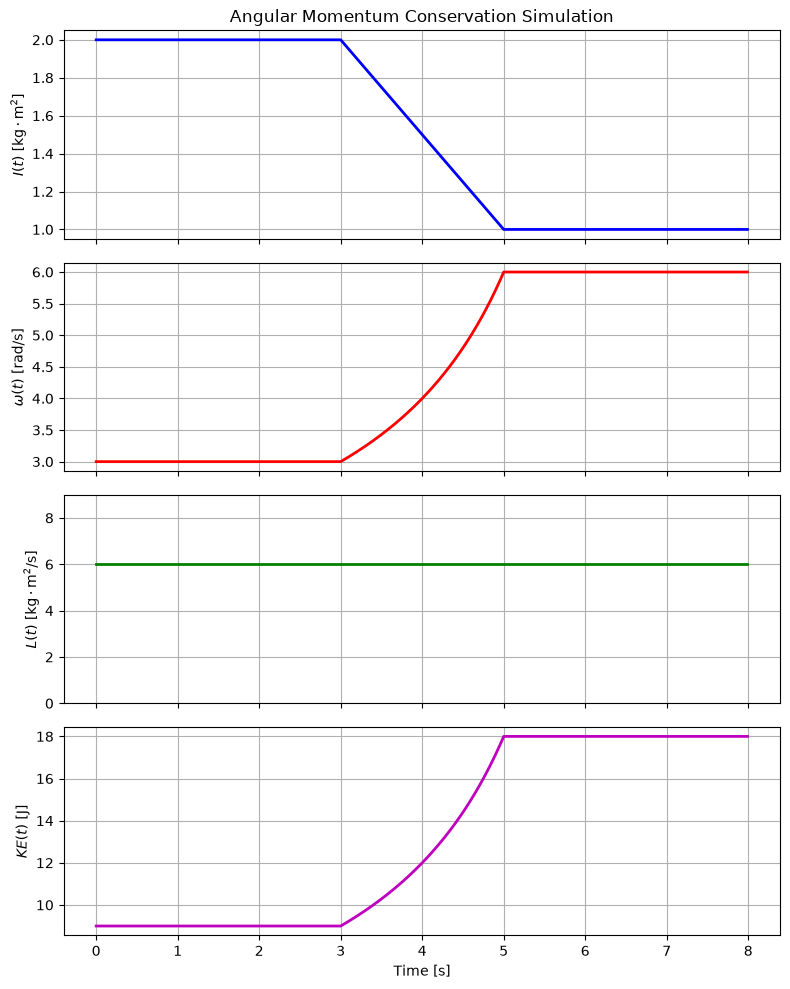

In [16]:
# --- 1. Simulation Parameters ---
t_max = 8.0          # total time in seconds
dt = 0.01            # time step
t = np.arange(0, t_max, dt)
N = len(t)

# Initial conditions
I0 = 2.0             # initial moment of inertia (kg*m^2)
w0 = 3.0             # initial angular velocity (rad/s)
L0 = I0 * w0         # initial angular momentum (kg*m^2/s)

# --- 2. Define Time-Varying I(t) ---
# Halving I over a short interval (between t=3.0 and t=5.0)
I = np.zeros(N)
for i in range(N):
    if t[i] < 3.0:
        I[i] = I0
    elif t[i] <= 5.0:
        # Linear transition from I0 to I0/2
        I[i] = I0 - (I0 / 2.0) * ((t[i] - 3.0) / 2.0)
    else:
        I[i] = I0 / 2.0

# --- 3. Enforce Conservation to Calculate w, L, and KE ---
w = L0 / I
L = I * w
KE = 0.5 * I * (w**2)

# --- 4. Plotting on a Shared Timeline ---
fig, axs = plt.subplots(4, 1, figsize=(8, 10), sharex=True)

# Plot I(t)
axs[0].plot(t, I, 'b-', lw=2)
axs[0].set_ylabel(r'$I(t)$ [$\mathrm{kg\cdot m^2}$]')
axs[0].set_title('Angular Momentum Conservation Simulation')
axs[0].grid(True)

# Plot w(t)
axs[1].plot(t, w, 'r-', lw=2)
axs[1].set_ylabel(r'$\omega(t)$ [$\mathrm{rad/s}$]')
axs[1].grid(True)

# Plot L(t)
axs[2].plot(t, L, 'g-', lw=2)
axs[2].set_ylabel(r'$L(t)$ [$\mathrm{kg\cdot m^2/s}$]')
axs[2].set_ylim(0, L0 * 1.5)  # Pad to visually confirm flatness
axs[2].grid(True)

# Plot KE(t)
axs[3].plot(t, KE, 'm-', lw=2)
axs[3].set_ylabel(r'$KE(t)$ [$\mathrm{J}$]')
axs[3].set_xlabel('Time [s]')
axs[3].grid(True)

plt.tight_layout()
plt.show()


**Confirm and explain**:  L stays constant, ω rises when I drops, but KE increases.  Where does the extra kinetic energy come from?  Why doesn't this violate energy conservation?

The momentum is held constant because the as the size of the distribution of weight changes the weight doesn’t. Kinetic energy increases as there is work done to decrease the radius of rotation. The total system conserves energy but with our view it seems energy is created. 


| Conservation Law | Diagnostic Role | Example Bug Caught |
| :--- | :--- | :--- |
| **Total Energy** | Tracks system stability and numerical validity across time steps. | **Exploding Integrator Loop:** Using an standard Euler step instead of Euler-Cromer causes the orbital path to spiral outward indefinitely due to non-physical, artificial energy addition. |
| **Linear Momentum** | Validates internal forces cancel out without external net interactions. | **Incorrect Collision Physics:** A coding typo in an elastic collision calculation where a velocity sign is swapped, causing two objects to speed away in the same direction after hitting each other. |
| **Angular Momentum** | Monitors rotational consistency when geometries or configurations change. | **Asymmetric Forces:** An orbital mechanics simulation where a planet experiences a non-central force due to cross-product coordinate sign errors, leading to a false torque that alters orbital shape. |
